## Imports

In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.linear_model import Ridge
from sklearn.linear_model import Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression



from sklearn.ensemble import RandomForestRegressor
from sklearn.ensemble import GradientBoostingRegressor  
from sklearn.ensemble import AdaBoostRegressor
from sklearn.ensemble import ExtraTreesRegressor
from sklearn.ensemble import StackingRegressor
from sklearn.ensemble import VotingRegressor
from xgboost import XGBRegressor

from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report, confusion_matrix, f1_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.ensemble import AdaBoostClassifier
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.ensemble import StackingClassifier
from sklearn.ensemble import VotingClassifier


from sklearn.svm import SVC
import joblib
import os
import urllib
import json 
import re
import warnings
import requests
import time
from bs4 import BeautifulSoup
from urllib.parse import quote
from urllib.parse import quote_plus
import random
from concurrent.futures import ThreadPoolExecutor, as_completed
from sklearn.pipeline import Pipeline

# Preprocessing and preparing data 

In [6]:
df = pd.read_csv('data/epi_r.csv')

# for col in df.columns:
#     print(col)

ingredients = [
'almond','anchovy','anise','apple','apple juice','apricot','artichoke','arugula','asian pear','asparagus','avocado',
'bacon','banana','barley','basil','bean','beef','beef rib','beef shank','beef tenderloin','beet','bell pepper','berry',
'blackberry','blue cheese','blueberry','bok choy','bran','bread','breadcrumbs','brie','brisket','broccoli','broccoli rabe',
'brown rice','brussel sprout','bulgur','butter','buttermilk','butternut squash','cabbage','cantaloupe','capers','caraway',
'cardamom','carrot','cashew','cauliflower','caviar','celery','chard','cheddar','cheese','cherry','chestnut','chicken',
'chickpea','chile','chile pepper','chili','chive','chocolate','cilantro','cinnamon','citrus','clam','clove','coconut',
'cod','coffee','collard greens','coriander','corn','cornmeal','cottage cheese','couscous','crab','cranberry',
'cranberry sauce','cream cheese','cucumber','cumin','currant','curry','custard','date','dill','duck','egg','eggplant',
'endive','escarole','fennel','feta','fig','fish','fontina','garlic','ginger','goat cheese','goose','gouda',
'grape','grapefruit','green bean','green onion/scallion','ground beef','ground lamb','guava','halibut','ham','hazelnut',
'herb','honey','honeydew','horseradish','hot pepper','hummus','ice cream','jalapeño','jerusalem artichoke','kale',
'kiwi','kumquat','lamb','lamb chop','lamb shank','leek','lemon','lemon juice','lemongrass','lentil','lettuce',
'lima bean','lime','lime juice','lingonberry','lobster','macadamia nut','mango','maple syrup','mayonnaise','meat',
'melon','milk/cream','mint','molasses','monterey jack','mozzarella','mushroom','mussel','mustard','mustard greens',
'nectarine','nut','nutmeg','oat','oatmeal','octopus','okra','olive','onion','orange','orange juice','oregano','orzo',
'oyster','papaya','paprika','parmesan','parsley','parsnip','passion fruit','pasta','pea','peach','peanut',
'peanut butter','pear','pecan','pepper','persimmon','pine nut','pineapple','pistachio','plantain','plum','poblano',
'pomegranate','pomegranate juice','poppy','pork','pork chop','pork rib','pork tenderloin','potato','poultry',
'prosciutto','prune','pumpkin','quail','quince','quinoa','rabbit','radicchio','radish','raisin','raspberry','rhubarb',
'rice','ricotta','root vegetable','rosemary','rutabaga','rye','saffron','sage','salmon','sardine','sausage','scallop',
'seafood','seed','semolina','sesame','sesame oil','shallot','shellfish','shrimp','snapper','sorbet','sour cream',
'sourdough','soy','soy sauce','spinach','squash','squid','steak','strawberry','sugar conscious','sugar snap pea','sweet potato/yam',
'swiss cheese','swordfish','tamarind','tangerine','tapioca','tarragon','tea','thyme','tilapia','tofu','tomatillo',
'tomato','tortillas','trout','tuna','turnip','vanilla','veal','vegetable','venison','vinegar','walnut','wasabi',
'watercress','watermelon','whole wheat','wild rice','yogurt','yuca','zucchini','turkey'
]

df_selected = df[ingredients + ['rating']]
df_selected = df_selected.dropna()

# for element in df_selected.columns:
#     print(element)

# print(df_selected.head())
# print(df_selected.describe())
# print(df_selected.info())    
# print(df_selected.shape)
# print(df_selected.columns)   

X = df_selected[ingredients]
y = df_selected['rating']
print(X.shape)
print(y.shape)  

# df_selected.to_csv('data/recipes_selected.csv', index=False)    

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


(20052, 274)
(20052,)


# Regression

Try different algorithms and their hyperparameters for rating prediction.

In [7]:
# =========================
# RIDGE MODEL
# =========================

ridge = Ridge()
ridge_params = {
    'alpha': [0.1, 1.0, 10.0, 100.0]
}

ridge_grid = GridSearchCV(
    ridge,
    ridge_params,
    scoring='neg_root_mean_squared_error',
    cv=5
)

ridge_grid.fit(X_train_scaled, y_train)

print("Best Ridge:", ridge_grid.best_params_)
print("Best Ridge RMSE:", -ridge_grid.best_score_)


# =========================
# LINEAR MODEL  
# =========================
linear = LinearRegression()

scores = cross_val_score(
    linear,
    X_train_scaled,
    y_train,
    scoring='neg_root_mean_squared_error',
    cv=5
)

linear_rmse = -scores.mean()
print("Linear Regression RMSE:", linear_rmse)


# =========================
# DECISION TREE REGRESSOR MODEL
# =========================


tree = DecisionTreeRegressor(random_state=42)
tree_params = {
    'max_depth': [None, 5, 10, 20],
    'min_samples_split': [2, 5, 10]
}

tree_grid = GridSearchCV(
    tree,
    tree_params, 
    scoring='neg_root_mean_squared_error',
    cv=5,
    n_jobs=-1
)

tree_grid.fit(X_train_scaled, y_train)

print("Best Tree:", tree_grid.best_params_)
print("Best Tree RMSE:", -tree_grid.best_score_)
    

# =========================
# LASSO MODEL
# =========================
lasso = Lasso(max_iter=10000)
lasso_params = {
    'alpha': [0.001, 0.01, 0.1, 1.0, 10.0]
    
}

lasso_grid = GridSearchCV(
    lasso,
    lasso_params,
    scoring='neg_root_mean_squared_error',
    cv=5,
    n_jobs=-1
)

lasso_grid.fit(X_train_scaled, y_train)
print("Best Lasso:", lasso_grid.best_params_)
print("Best Lasso RMSE:", -lasso_grid.best_score_)


Best Ridge: {'alpha': 100.0}
Best Ridge RMSE: 1.3201951610383045
Linear Regression RMSE: 1.32045756271743
Best Tree: {'max_depth': 5, 'min_samples_split': 2}
Best Tree RMSE: 1.3444734610176445
Best Lasso: {'alpha': 0.01}
Best Lasso RMSE: 1.3176980604550343


Select the best one based on cross-validation and determine the score (RMSE) using the test subsample.

In [9]:
best_model = lasso_grid.best_estimator_
y_pred = best_model.predict(X_test_scaled)

rmse = np.sqrt(mean_squared_error(y_test, y_pred))
print("Test RMSE:", rmse)


Test RMSE: 1.2794926072597912


Try different ensembles and their hyperparameters. Select the best one using cross-validation and calculate the RMSE on the test subsample.

In [ ]:
%%time
# =========================
# RANDOM FOREST REGRESSOR MODEL
# =========================
rf = RandomForestRegressor(random_state=42)
rf_params = {
    'n_estimators': [50, 100, 150, 200], 
    'max_depth': [5, 10, None],
    'min_samples_split': [2, 5]
}

rf_grid = GridSearchCV(
    rf,
    rf_params,
    scoring='neg_root_mean_squared_error',
    cv=5,
    n_jobs=-1
)

print("Fitting Random Forest...")
rf_grid.fit(X_train, y_train)
print("RF RMSE:", -rf_grid.best_score_)
print('\n')


# =========================
# GRADIENT BOOSTING REGRESSOR MODEL
# =========================

gbr = GradientBoostingRegressor(random_state=42)
gbr_params = {
    'n_estimators': [50, 100, 150],
    'learning_rate': [0.01, 0.1, 0.2],
    'max_depth': [3, 5]
}

gbr_grid = GridSearchCV(
    gbr,
    gbr_params,
    scoring='neg_root_mean_squared_error',
    cv=5,
    n_jobs=-1
)
print("Fitting Gradient Boosting...")
gbr_grid.fit(X_train, y_train)
print("GBR RMSE:", -gbr_grid.best_score_)
print('\n')


#==========================
# ADA BOOST REGRESSOR MODEL
#==========================
ada = AdaBoostRegressor(random_state=42)
ada_params = {
    'n_estimators': [50, 100, 150],
    'learning_rate': [0.01, 0.1, 0.2]
}
ada_grid = GridSearchCV(
    ada,
    ada_params,
    scoring='neg_root_mean_squared_error',
    cv=5,
    n_jobs=-1
)
print("Fitting AdaBoost...")
ada_grid.fit(X_train, y_train)
print("ADA RMSE:", -ada_grid.best_score_)
print('\n')

#========================== 
# EXTRA TREES REGRESSOR MODEL
#==========================

extra_trees = ExtraTreesRegressor(random_state=42)
extra_trees_params = {
    'n_estimators': [50, 100, 150],
    'max_depth': [5, 10, None],
    'min_samples_split': [2, 5]
}   
extra_trees_grid = GridSearchCV(
    extra_trees,
    extra_trees_params,
    scoring='neg_root_mean_squared_error',
    cv=5,
    n_jobs=-1
)
print("Fitting Extra Trees...")
extra_trees_grid.fit(X_train, y_train)
print("Extra Trees RMSE:", -extra_trees_grid.best_score_)   
print('\n')


#==========================
# XGBOOST REGRESSOR MODEL
#========================== 

xgb = XGBRegressor(random_state=42, objective='reg:squarederror')
xgb_params = {
    'n_estimators': [50, 100, 150],
    'learning_rate': [0.01, 0.1, 0.2],
    'max_depth': [3, 5]
}
xgb_grid = GridSearchCV(
    xgb,
    xgb_params,
    scoring='neg_root_mean_squared_error',
    cv=5,
    n_jobs=-1
)
print("Fitting XGBoost...")
xgb_grid.fit(X_train, y_train)
print("XGBoost RMSE:", -xgb_grid.best_score_)
print('\n')



Select the best one using cross-validation and calculate the RMSE on the test subsample.

In [ ]:
best_model = xgb_grid.best_estimator_
best_model.fit(X_train, y_train)
y_pred = best_model.predict(X_test)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
print("Test RMSE:", rmse)


Calculate the RMSE for a naive regressor that predicts the average rating.

In [ ]:
mean_value = y_train.mean()
y_pred_naive = np.full_like(y_test, mean_value, dtype=float)
rmse_naive = np.sqrt(mean_squared_error(y_test, y_pred_naive))
print("Naive Mean RMSE:", rmse_naive)

# Classification

Binarize the target column by rounding the ratings to the closest integer. These will be your classes.

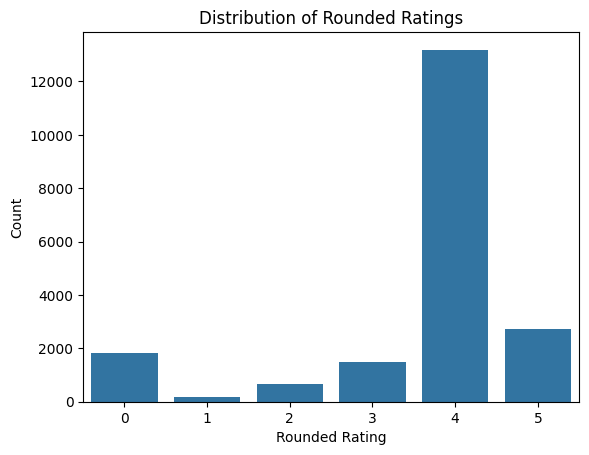

In [16]:
df_selected['round_rating'] = df_selected['rating'].round().astype(int)
sns.countplot(x='round_rating', data=df_selected)
plt.title('Distribution of Rounded Ratings')
plt.xlabel('Rounded Rating')
plt.ylabel('Count')
plt.show()

# print(df.columns)

X = df_selected.drop(columns=['rating', 'round_rating'])
y = df_selected['round_rating']

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)  
X_test_scaled = scaler.transform(X_test)


Try different algorithms and their hyperparameters for class prediction. Select the best algorithm based on cross-validation and determine the accuracy score on the test subsample.

In [17]:

# =========================
# LogisticRegression for classification
# =========================


lr = LogisticRegression(max_iter=10000, solver='lbfgs')
lr_params = {
    'C': [0.01, 0.1, 1.0, 10.0],
    'penalty': ['l2']
}

lr_grid = GridSearchCV(
    lr,
    lr_params,
    scoring='accuracy',
    cv=5,
    n_jobs=-1
)
print("Fitting Logistic Regression...")
lr_grid.fit(X_train_scaled, y_train)
print("Best Logistic Regression:", lr_grid.best_score_)
print('\n')



Fitting Logistic Regression...
Best Logistic Regression: 0.6563802398024882




In [ ]:
#==========================
#SVM for classification
#==========================

svm = SVC(kernel='rbf', random_state=42)
svm_params = {
    'C': [0.1, 1.0, 10.0],
    'gamma': ['scale', 'auto']
}
svm_grid = GridSearchCV(
    svm,
    svm_params,
    scoring='accuracy',
    cv=5,
    n_jobs=-1
)
print("Fitting SVM...")
svm_grid.fit(X_train_scaled, y_train)
print("Best SVM:", svm_grid.best_score_)
print('\n') 

In [20]:
#=================================
# Decision Tree for classification
#=================================

tree_df = DecisionTreeClassifier(random_state=42)
tree_df_params = {
    'max_depth': [None, 5, 10, 20],
    'min_samples_split': [2, 5, 10]
}
tree_df_grid = GridSearchCV(
    tree_df,
    tree_df_params,
    scoring='accuracy',
    cv=5,
    n_jobs=-1
)
print("Fitting Decision Tree Classifier...")
tree_df_grid.fit(X_train, y_train)
print("Best Decision Tree:", tree_df_grid.best_score_)
print('\n')

Fitting Decision Tree Classifier...
Best Decision Tree: 0.6549466937206687




In [ ]:
#=================================
# Random Forest for classification
#=================================

random_forest  = RandomForestClassifier(random_state=42)
random_forest_params = {
    'n_estimators': [50, 100, 150, 200],
    'max_depth': [5, 10, None],
    'min_samples_split': [2, 5]
}
random_forest_grid = GridSearchCV(
    random_forest,
    random_forest_params,
    scoring='accuracy',
    cv=5,
    n_jobs=-1
)
print("Fitting Random Forest Classifier...")
random_forest_grid.fit(X_train, y_train)
print("Best Random Forest:", random_forest_grid.best_score_)
print('\n') 

In [23]:
#=============================
# KNN classification
#=============================

knn = KNeighborsClassifier()
knn_params = {
    'n_neighbors': [3, 5, 7],
    'weights': ['uniform', 'distance']
}
knn_grid = GridSearchCV(
    knn,
    knn_params,
    scoring='accuracy',
    cv=5,
    n_jobs=-1
)
print("Fitting KNN Classifier...")
knn_grid.fit(X_train_scaled, y_train)
print("Best KNN:", knn_grid.best_score_)
print('\n')

Fitting KNN Classifier...
Best KNN: 0.6242753198027058




In [ ]:
best_model = random_forest_grid.best_estimator_

y_pred = best_model.predict(X_test)

from sklearn.metrics import accuracy_score
print("Test Accuracy:", accuracy_score(y_test, y_pred))

Compare the metrics using accuracy. Calculate the accuracy of a naïve classifier that predicts the most common class.


In [ ]:
# Now we are gonna compare the best regression model with a naive baseline that predicts the mean rating for all test samples.

most_common_class = y_train.value_counts().idxmax()
print("Most common class:", most_common_class)

y_pred_naive = np.full_like(y_test, most_common_class, dtype=int)   
naive_accuracy = accuracy_score(y_test, y_pred_naive)
print("Naive Accuracy:", naive_accuracy)

Most common class: 4
Naive Accuracy: 0.6641735228122663


Binarize the target column by converting the integers to the following classes: “bad” (0, 1), “so-so” (2, 3), and “great” (4, 5).

In [26]:

df_selected['rating_label'] = df_selected['round_rating'].apply(
    lambda x: 'bad' if x in [0,1]
    else 'so-so' if x in [2,3]
    else 'great'
)

# for element in df_selected.columns:
#     print(element)
# print(df_selected.head())


X = df_selected.drop(columns=['rating', 'round_rating', 'rating_label'])
y = df_selected['rating_label']
# print(df_selected.columns)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)



Try different algorithms and their hyperparameters for class prediction. Select the best algorithm using cross-validation and determine the score on the test subsample.

In [27]:

# =========================
# LogisticRegression for classification for labels (bad, so-so, great)
# =========================

from sklearn.tree import DecisionTreeClassifier


lr = LogisticRegression(max_iter=10000, solver='lbfgs')
lr_params = {
    'C': [0.01, 0.1, 1.0, 10.0],
    'penalty': ['l2']
}

lr_grid = GridSearchCV(
    lr,
    lr_params,
    scoring='accuracy',
    cv=5,
    n_jobs=-1
)
print("Fitting Logistic Regression...")
lr_grid.fit(X_train_scaled, y_train)
print("Best Logistic Regression:", lr_grid.best_score_)
print('\n')


Fitting Logistic Regression...
Best Logistic Regression: 0.7907236427472919




In [ ]:
#==========================
#SVM for classification for labels (bad, so-so, great)
#==========================

svm = SVC(kernel='rbf', random_state=42)
svm_params = {
    'C': [0.1, 1.0, 10.0],
    'gamma': ['scale', 'auto']
}
svm_grid = GridSearchCV(
    svm,
    svm_params,
    scoring='accuracy',
    cv=5,
    n_jobs=-1
)
print("Fitting SVM...")
svm_grid.fit(X_train_scaled, y_train)
print("Best SVM:", svm_grid.best_score_)
print('\n') 

In [30]:
#==========================
# Decision Tree for classification for labels (bad, so-so, great)
#==========================

tree_df = DecisionTreeClassifier(random_state=42)
tree_df_params = {
    'max_depth': [None, 5, 10, 20],
    'min_samples_split': [2, 5, 10]
}
tree_df_grid = GridSearchCV(
    tree_df,
    tree_df_params,
    scoring='accuracy',
    cv=5,
    n_jobs=-1
)
print("Fitting Decision Tree Classifier...")
tree_df_grid.fit(X_train, y_train)
print("Best Decision Tree:", tree_df_grid.best_score_)
print('\n')

Fitting Decision Tree Classifier...
Best Decision Tree: 0.790661415175057




In [31]:
#=================================
# Random Forest for classification for labels (bad, so-so, great)
#=================================

random_forest  = RandomForestClassifier(random_state=42)
random_forest_params = {
    'n_estimators': [50, 100, 150, 200],
    'max_depth': [5, 10, None],
    'min_samples_split': [2, 5]
}
random_forest_grid = GridSearchCV(
    random_forest,
    random_forest_params,
    scoring='accuracy',
    cv=5,
    n_jobs=-1
)
print("Fitting Random Forest Classifier...")
random_forest_grid.fit(X_train, y_train)
print("Best Random Forest:", random_forest_grid.best_score_)
print('\n') 

Fitting Random Forest Classifier...
Best Random Forest: 0.7911601682922641




In [32]:
#=============================
# KNN classification for labels (bad, so-so, great)
#=============================

knn = KNeighborsClassifier()
knn_params = {
    'n_neighbors': [3, 5, 7],
    'weights': ['uniform', 'distance']
}
knn_grid = GridSearchCV(
    knn,
    knn_params,
    scoring='accuracy',
    cv=5,
    n_jobs=-1
)
print("Fitting KNN Classifier...")
knn_grid.fit(X_train_scaled, y_train)
print("Best KNN:", knn_grid.best_score_)
print('\n')

Fitting KNN Classifier...
Best KNN: 0.772520669345645




In [34]:
# best_model = svm_grid.best_estimator_
# y_pred = best_model.predict(X_test_scaled)
# print("Test Accuracy:", accuracy_score(y_test, y_pred))

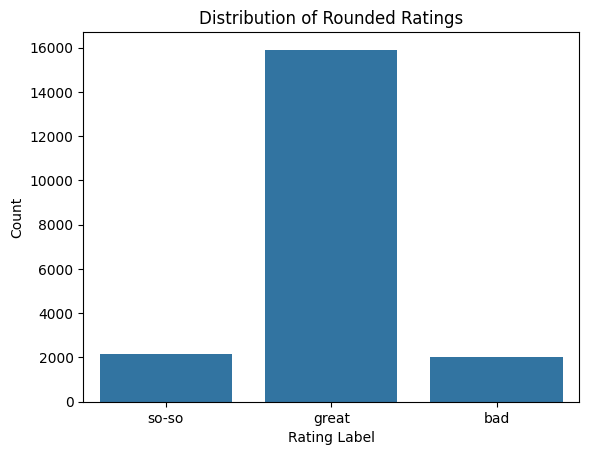

In [35]:
sns.countplot(x='rating_label', data=df_selected)
plt.title('Distribution of Rounded Ratings')
plt.xlabel('Rating Label')
plt.ylabel('Count')
plt.show()

In [36]:
most_common_class = y_train.value_counts().idxmax()
print("Most common class:", most_common_class)

#naive prediction
y_pred_naive = np.array([most_common_class] * len(y_test))

#accuracy
naive_accuracy = accuracy_score(y_test, y_pred_naive)
print("Naive Accuracy:", naive_accuracy)


Most common class: great
Naive Accuracy: 0.8017950635751683


What is worse: predicting a bad rating that is actually good or predicting a good rating that is actually bad? Replace accuracy with the appropriate metric.

Try different algorithms and their hyperparameters for class prediction with the new metric. Select the best algorithm and find its score on the test subsample.

In [37]:

# =========================
# LogisticRegression for classification for labels (bad, so-so, great)   -   now with the f1_weighted scoring to handle class imbalance
# =========================

lr = LogisticRegression(max_iter=10000, solver='lbfgs')
lr_params = {
    'C': [0.01, 0.1, 1.0, 10.0],
    'penalty': ['l2']
}

lr_grid = GridSearchCV(
    lr,
    lr_params,
    scoring='f1_weighted',
    cv=5,
    n_jobs=-1
)
print("Fitting Logistic Regression...")
lr_grid.fit(X_train_scaled, y_train)
print("Best Logistic Regression with f1_weighted scoring:", lr_grid.best_score_)
print('\n')


Fitting Logistic Regression...
Best Logistic Regression with f1_weighted scoring: 0.7079038748569997




In [ ]:
#==========================
#SVM for classification for labels (bad, so-so, great)   -   now with the f1_weighted scoring to handle class imbalance
#========================== 

svm = SVC(kernel='rbf', random_state=42)
svm_params = {
    'C': [0.1, 1.0, 10.0],
    'gamma': ['scale', 'auto']
}
svm_grid = GridSearchCV(
    svm,
    svm_params,
    scoring='f1_weighted',
    cv=5,
    n_jobs=-1
)
print("Fitting SVM...")
svm_grid.fit(X_train_scaled, y_train)
print("Best SVM with f1_weighted scoring:", svm_grid.best_score_)
print('\n') 

Fitting SVM...
Best SVM with f1_weighted scoring: 0.7198129484031537




In [38]:
#==========================
# Decision Tree for classification for labels (bad, so-so, great)   -   now with the f1_weighted scoring to handle class imbalance
#==========================

tree_df = DecisionTreeClassifier(random_state=42)
tree_df_params = {
    'max_depth': [None, 5, 10, 20],
    'min_samples_split': [2, 5, 10]
}
tree_df_grid = GridSearchCV(
    tree_df,
    tree_df_params,
    scoring='f1_weighted',
    cv=5,
    n_jobs=-1
)
print("Fitting Decision Tree Classifier...")
tree_df_grid.fit(X_train, y_train)
print("Best Decision Tree with f1_weighted scoring:", tree_df_grid.best_score_)
print('\n')

Fitting Decision Tree Classifier...
Best Decision Tree with f1_weighted scoring: 0.7067619857503091




In [39]:
#=================================
# Random Forest for classification for labels (bad, so-so, great) -   now with the f1_weighted scoring to handle class imbalance
#=================================

random_forest  = RandomForestClassifier(random_state=42)
random_forest_params = {
    'n_estimators': [50, 100, 150, 200],
    'max_depth': [5, 10, None],
    'min_samples_split': [2, 5]
}
random_forest_grid = GridSearchCV(
    random_forest,
    random_forest_params,
    scoring='f1_weighted',
    cv=5,
    n_jobs=-1
)
print("Fitting Random Forest Classifier...")
random_forest_grid.fit(X_train, y_train)
print("Best Random Forest with f1_weighted scoring:", random_forest_grid.best_score_)
print('\n') 

Fitting Random Forest Classifier...
Best Random Forest with f1_weighted scoring: 0.7355360944139144




In [ ]:
#=============================
# KNN classification for labels (bad, so-so, great)  -  now with the f1_weighted scoring to handle class imbalance
#=============================

knn = KNeighborsClassifier()
knn_params = {
    'n_neighbors': [3, 5, 7],
    'weights': ['uniform', 'distance']
}
knn_grid = GridSearchCV(
    knn,
    knn_params,
    scoring='f1_weighted',
    cv=5,
    n_jobs=-1
)
print("Fitting KNN Classifier...")
knn_grid.fit(X_train_scaled, y_train)
print("Best KNN with f1_weighted scoring:", knn_grid.best_score_)
print('\n')

Fitting KNN Classifier...
Best KNN with f1_weighted scoring: 0.7329852129973862




Now gonna test best model with the new metric on the test set

In [ ]:
best_model = random_forest_grid.best_estimator_
y_pred  = best_model.predict(X_test)
f1 = f1_score(y_test, y_pred, average='weighted')
print("Test F1 Score:", f1)

Test F1 Score: 0.7465472607490122


Try different ensembles and their hyperparameters. Select the best one and find its score on the test subsample.

In [40]:
# =========================
# RANDOM FOREST CLASSIFIER MODEL  (Ensemble method with f1_weighted scoring for classification to handle class imbalance)
# =========================
rf = RandomForestClassifier(random_state=42)
rf_params = {
    'n_estimators': [50, 100, 150, 200], 
    'max_depth': [5, 10, None],
    'min_samples_split': [2, 5]
}

rf_grid = GridSearchCV(
    rf,
    rf_params,
    scoring='f1_weighted',
    cv=5,
    n_jobs=-1
)

print("Fitting Random Forest...")
rf_grid.fit(X_train, y_train)
print("RF F1 Score:", rf_grid.best_score_)
print('\n')

Fitting Random Forest...
RF F1 Score: 0.7355360944139144




In [ ]:
# =========================
# GRADIENT BOOSTING CLASSIFIER MODEL (Ensemble method with f1_weighted scoring for classification to handle class imbalance)
# =========================

gbr = GradientBoostingClassifier(random_state=42)
gbr_params = {
    'n_estimators': [50, 100, 150],
    'learning_rate': [0.01, 0.1, 0.2],
    'max_depth': [3, 5]
}

gbr_grid = GridSearchCV(
    gbr,
    gbr_params,
    scoring='f1_weighted',
    cv=5,
    n_jobs=-1
)
print("Fitting Gradient Boosting...")
gbr_grid.fit(X_train, y_train)
print("GBR F1 Score:", gbr_grid.best_score_)
print('\n')


Fitting Gradient Boosting...
GBR F1 Score: 0.710956936896831




In [ ]:
#==========================
# ADA BOOST CLASSIFIER MODEL (Ensemble method with f1_weighted scoring for classification to handle class imbalance)
#==========================
ada = AdaBoostClassifier(random_state=42)
ada_params = {
    'n_estimators': [50, 100, 150],
    'learning_rate': [0.01, 0.1, 0.2]
}
ada_grid = GridSearchCV(
    ada,
    ada_params,
    scoring='f1_weighted',
    cv=5,
    n_jobs=-1
)
print("Fitting AdaBoost...")
ada_grid.fit(X_train, y_train)
print("ADA F1 Score:", ada_grid.best_score_)
print('\n')

Fitting AdaBoost...
ADA F1 Score: 0.6989150750067477




In [ ]:
#========================== 
# EXTRA TREES REGRESSOR MODEL  (Ensemble method with f1_weighted scoring for classification to handle class imbalance)
#==========================

extra_trees = ExtraTreesClassifier(random_state=42)
extra_trees_params = {
    'n_estimators': [50, 100, 150],
    'max_depth': [5, 10, None],
    'min_samples_split': [2, 5]
}   
extra_trees_grid = GridSearchCV(
    extra_trees,
    extra_trees_params,
    scoring='f1_weighted',
    cv=5,
    n_jobs=-1
)
print("Fitting Extra Trees...")
extra_trees_grid.fit(X_train, y_train)
print("Extra Trees F1 Score:", extra_trees_grid.best_score_)   
print('\n')


Fitting Extra Trees...
Extra Trees F1 Score: 0.7345530410805184




In [ ]:
#==========================
# STACKING CLASSIFIER MODEL   (Ensemble method with f1_weighted scoring for classification to handle class imbalance)
#========================== 

stacking_classifier = StackingClassifier(
    estimators=[
        ('rf', rf_grid.best_estimator_),
        ('ada', ada_grid.best_estimator_),
        ('extra', extra_trees_grid.best_estimator_)
    ],
    final_estimator=LogisticRegression(max_iter=10000)
)
print("Fitting Stacking Classifier...")
scores = cross_val_score(
    stacking_classifier,
    X_train,
    y_train,
    cv=5,
    scoring='f1_weighted',
    n_jobs=-1
)
print("Stacking CV F1:", scores.mean())



Fitting Stacking Classifier...
Stacking CV F1: 0.7168573698275293


In [41]:
# Now we are gonna use the best classification model with the test set 

os.makedirs('models', exist_ok=True)


final_model = Pipeline([
    ('scaler', scaler),              # your fitted scaler
    ('model', rf_grid.best_estimator_)
])

# =========================
# Fit on FULL training data
# =========================
final_model.fit(X_train, y_train)

# =========================
# Save model
# =========================
joblib.dump(final_model, 'models/best_rf_model.pkl')

print("✅ Model saved to models/best_rf_model.pkl")

# =========================
# Evaluate on test set
# =========================
y_pred = final_model.predict(X_test)

f1 = f1_score(y_test, y_pred, average='weighted')
print("Test F1 Score:", f1)

✅ Model saved to models/best_rf_model.pkl
Test F1 Score: 0.7465472607490122


# Model has been saved now we are gonna work on the API calls

In [3]:
df_ingredients = pd.read_csv('data/epi_r.csv')
# print(df_ingredients.head())
# for col in df_ingredients.columns:
#     print(col)

ingredients = [
'almond','anchovy','anise','apple','apple juice','apricot','artichoke','arugula','asian pear','asparagus','avocado',
'bacon','banana','barley','basil','bean','beef','beef rib','beef shank','beef tenderloin','beet','bell pepper','berry',
'blackberry','blue cheese','blueberry','bok choy','bran','bread','breadcrumbs','brie','brisket','broccoli','broccoli rabe',
'brown rice','brussel sprout','bulgur','butter','buttermilk','butternut squash','cabbage','cantaloupe','capers','caraway',
'cardamom','carrot','cashew','cauliflower','caviar','celery','chard','cheddar','cheese','cherry','chestnut','chicken',
'chickpea','chile','chile pepper','chili','chive','chocolate','cilantro','cinnamon','citrus','clam','clove','coconut',
'cod','coffee','collard greens','coriander','corn','cornmeal','cottage cheese','couscous','crab','cranberry',
'cranberry sauce','cream cheese','cucumber','cumin','currant','curry','custard','date','dill','duck','egg','eggplant',
'endive','escarole','fennel','feta','fig','fish','flour','fontina','garlic','ginger','goat cheese','goose','gouda',
'grape','grapefruit','green bean','green onion/scallion','ground beef','ground lamb','guava','halibut','ham','hazelnut',
'herb','honey','honeydew','horseradish','hot pepper','hummus','ice cream','jalapeño','jerusalem artichoke','kale',
'kiwi','kumquat','lamb','lamb chop','lamb shank','leek','lemon','lemon juice','lemongrass','lentil','lettuce',
'lima bean','lime','lime juice','lingonberry','lobster','macadamia nut','mango','maple syrup','mayonnaise','meat',
'melon','milk/cream','mint','molasses','monterey jack','mozzarella','mushroom','mussel','mustard','mustard greens',
'nectarine','nut','nutmeg','oat','oatmeal','octopus','okra','olive','onion','orange','orange juice','oregano','orzo',
'oyster','papaya','paprika','parmesan','parsley','parsnip','passion fruit','pasta','pea','peach','peanut',
'peanut butter','pear','pecan','pepper','persimmon','pine nut','pineapple','pistachio','plantain','plum','poblano',
'pomegranate','pomegranate juice','poppy','pork','pork chop','pork rib','pork tenderloin','potato','poultry',
'prosciutto','prune','pumpkin','quail','quince','quinoa','rabbit','radicchio','radish','raisin','raspberry','rhubarb',
'rice','ricotta','root vegetable','rosemary','rutabaga','rye','saffron','sage','salmon','sardine','sausage','scallop',
'seafood','seed','semolina','sesame','sesame oil','shallot','shellfish','shrimp','snapper','sorbet','sour cream',
'sourdough','soy','soy sauce','spinach','squash','squid','steak','strawberry','sugar','sugar snap pea','sweet potato/yam',
'swiss cheese','swordfish','tamarind','tangerine','tapioca','tarragon','tea','thyme','tilapia','tofu','tomatillo',
'tomato','tortillas','trout','tuna','turnip','vanilla','veal','vegetable','venison','vinegar','walnut','wasabi',
'watercress','watermelon','wheat','wild rice','yogurt','yuca','zucchini','turkey'
]


Now we are gonna work on the Nutrition Facts part

In [ ]:
API_KEY = '2EY4gVSDFdgAnnMz8va0UwIGviDbplqbd2BVNPhs'

# Reference Daily Values (DRV) and Reference Daily Intakes (RDI)
# ALL CONVERTED TO MILLIGRAMS AS BASE UNIT for consistency

DRV_VALUES = {
    # GRAMS → multiply by 1000 to get mg
    'fat': 78 * 1000,                    # 78 g → 78,000 mg
    'saturated fat': 20 * 1000,          # 20 g → 20,000 mg
    'carbohydrate': 275 * 1000,          # 275 g → 275,000 mg
    'fiber': 28 * 1000,                  # 28 g → 28,000 mg
    'protein': 50 * 1000,                # 50 g → 50,000 mg
    'sugar': 50 * 1000,                  # 50 g (added sugars) → 50,000 mg
    
    # ALREADY IN MILLIGRAMS
    'cholesterol': 300,                  # 300 mg
    'sodium': 2300,                      # 2,300 mg
}

RDI_VALUES = {
    # ========== ALREADY IN MILLIGRAMS ==========
    'vitamin c': 90,                     # 90 mg
    'calcium': 1300,                     # 1,300 mg
    'iron': 18,                          # 18 mg
    'vitamin e': 15,                     # 15 mg
    'thiamine': 1.2,                     # 1.2 mg
    'riboflavin': 1.3,                   # 1.3 mg
    'niacin': 16,                        # 16 mg
    'vitamin b6': 1.7,                   # 1.7 mg
    'pantothenic acid': 5,               # 5 mg
    'phosphorus': 1250,                  # 1,250 mg
    'magnesium': 420,                    # 420 mg
    'zinc': 11,                          # 11 mg
    'copper': 0.9,                       # 0.9 mg
    'manganese': 2.3,                    # 2.3 mg
    'chloride': 2300,                    # 2,300 mg
    'potassium': 4700,                   # 4,700 mg
    'choline': 550,                      # 550 mg
    
    # ========== MICROGRAMS → MILLIGRAMS (÷1000) ==========
    'vitamin a': 900 / 1000,             # 900 mcg → 0.9 mg
    'vitamin d': 20 / 1000,              # 20 mcg → 0.02 mg
    'vitamin k': 120 / 1000,             # 120 mcg → 0.12 mg
    'folate': 400 / 1000,                # 400 mcg → 0.4 mg
    'vitamin b12': 2.4 / 1000,           # 2.4 mcg → 0.0024 mg
    'biotin': 30 / 1000,                 # 30 mcg → 0.03 mg
    'iodine': 150 / 1000,                # 150 mcg → 0.15 mg
    'selenium': 55 / 1000,               # 55 mcg → 0.055 mg
    'chromium': 35 / 1000,               # 35 mcg → 0.035 mg
    'molybdenum': 45 / 1000,             # 45 mcg → 0.045 mg
}

ALL_REFERENCE_VALUES = {**DRV_VALUES, **RDI_VALUES}

def get_best_fdc_id(ingredient):
    """
    STEP 1: Search for ingredient → Get best FDC ID
    Uses /foods/search endpoint
    """
    url = "https://api.nal.usda.gov/fdc/v1/foods/search"
    params = {
        "api_key": API_KEY,
        "query": ingredient,
        "pageSize": 10
    }
    
    try:
        res = requests.get(url, params=params).json()
        
        if 'foods' not in res or not res['foods']:
            return None
        
        foods = res['foods']
        
        # Score each food to find best match
        def score_food(food):
            desc = food['description'].lower()
            query = ingredient.lower().strip()
            score = 0
            
            # Exact match = best
            if query in desc:
                score += 100
            
            # Prefer raw, unsalted versions
            if 'raw' in desc:
                score += 30
            if 'unsalted' in desc:
                score += 20
            
            # Avoid composite/processed versions
            bad_words = ['mix', 'sauce', 'seasoned', 'cooked']
            for word in bad_words:
                if word in desc:
                    score -= 20
            
            # API's own relevance score
            score += food.get('score', 0)
            
            return score
        
        best_food = max(foods, key=score_food)
        return best_food['fdcId']
    
    except Exception as e:
        print(f"Error searching for {ingredient}: {e}")
        return None


def normalize_to_100g(value, food_details):
    """Normalize nutrient to per 100g (robust)"""
    try:
        if 'servingSize' in food_details and food_details['servingSize']:
            serving = food_details['servingSize']
            unit = food_details.get('servingSizeUnit', '').lower()
            
            if unit == 'g' and serving != 100:
                return value * (100 / serving)
    except:
        pass
    return value


def get_nutrition_details(fdc_id):
    """
    STEP 2: Get full details → Use /food/{fdcId} endpoint
    """
    url = f"https://api.nal.usda.gov/fdc/v1/food/{fdc_id}"
    params = {'api_key': API_KEY}
    
    try:
        response = requests.get(url, params=params)
        response.raise_for_status()
        return response.json()
    except Exception as e:
        print(f"Error fetching FDC ID {fdc_id}: {e}")
        return None


def standardize_nutrient_name(name):
    """Normalize nutrient names for matching"""
    return name.lower().strip()


def convert_to_mg(value, unit):
    if value is None:
        return None
        
    unit = unit.lower() if unit else ""

    if unit == 'g':
        return value * 1000
    elif unit == 'mg':
        return value
    elif unit in ['mcg', 'µg']:
        return value / 1000
    elif unit == 'iu':
        return None  # ❌ skip IU (cannot convert safely)
    else:
        return None


def calculate_percent_daily_value(nutrient_name, value, unit):
    """Calculate % Daily Value (STRICT matching, no fuzzy logic)"""
    
    # normalize name
    norm_name = standardize_nutrient_name(nutrient_name)
    
    # ✅ DIRECT LOOKUP ONLY (FIXED)
    reference = ALL_REFERENCE_VALUES.get(norm_name)
    
    if reference is None:
        return None
    
    # ✅ convert value to mg
    converted_value = convert_to_mg(value, unit)
    
    if converted_value is None:
        return None
    
    # reference already in mg
    converted_reference = reference
    
    try:
        percent = (converted_value / converted_reference) * 100
        return percent
    except:
        return None

def collect_ingredient_nutrition(ingredients_list, output_file='data/ingredients_nutrition.csv'):
    """Collect nutrition for ALL ingredients (STRICT + CLEAN)"""
    
    NUTRIENT_MAPPING = {
        # MACROS
        'carbohydrate, by difference': 'carbohydrate',
        'total sugars': 'sugar',
        'fiber, total dietary': 'fiber',
        'total lipid (fat)': 'fat',
        'protein': 'protein',
        'cholesterol': 'cholesterol',
        'sodium, na': 'sodium',

        # VITAMINS
        'vitamin c, total ascorbic acid': 'vitamin c',
        'vitamin a, rae': 'vitamin a',
        'vitamin d (d2 + d3)': 'vitamin d',
        'vitamin e (alpha-tocopherol)': 'vitamin e',
        'vitamin k (phylloquinone)': 'vitamin k',
        'thiamin': 'thiamine',
        'riboflavin': 'riboflavin',
        'niacin': 'niacin',
        'vitamin b-6': 'vitamin b6',
        'vitamin b-12': 'vitamin b12',
        'folate, total': 'folate',
        'pantothenic acid': 'pantothenic acid',

        # MINERALS
        'calcium, ca': 'calcium',
        'iron, fe': 'iron',
        'magnesium, mg': 'magnesium',
        'phosphorus, p': 'phosphorus',
        'potassium, k': 'potassium',
        'zinc, zn': 'zinc',
        'copper, cu': 'copper',
        'manganese, mn': 'manganese',
        'selenium, se': 'selenium',
    }

    all_nutrition_data = []
    
    for i, ingredient in enumerate(ingredients_list):
        print(f"Processing {i+1}/{len(ingredients_list)}: {ingredient}...", end=' ')
        
        fdc_id = get_best_fdc_id(ingredient)
        if fdc_id is None:
            print("❌ No match")
            continue
        
        food_details = get_nutrition_details(fdc_id)
        if food_details is None:
            print("❌ No details")
            continue
        
        row = {'ingredient': ingredient}
        
        for nutrient in food_details.get('foodNutrients', []):
            if 'nutrient' not in nutrient or 'amount' not in nutrient:
                continue
            
            name = nutrient['nutrient'].get('name', '').lower()
            value = nutrient.get('amount')
            unit = nutrient['nutrient'].get('unitName', '')
            
            # ✅ STRICT MATCH (FINAL FIX)
            mapped = NUTRIENT_MAPPING.get(name)
            if mapped is None:
                continue
            
            # ✅ normalize
            value = normalize_to_100g(value, food_details)
            
            percent_dv = calculate_percent_daily_value(mapped, value, unit)
            
            if percent_dv is not None:
                row[mapped.replace(' ', '_')] = percent_dv
        
        all_nutrition_data.append(row)
        print("✓")
        time.sleep(0.2)
    
    df_nutrition = pd.DataFrame(all_nutrition_data).fillna(0)
    
    df_nutrition = df_nutrition.groupby('ingredient').mean().reset_index()
    df_nutrition = df_nutrition.round(1)
    df_nutrition.to_csv(output_file, index=False)
    
    print("\n✅ DONE")
    print(df_nutrition.shape)
    
    return df_nutrition


# Execute
df_ingredients_nutrition = collect_ingredient_nutrition(ingredients)
df_ingredients_nutrition.head()

Processing 1/275: almond... ✓
Processing 2/275: anchovy... ✓
Processing 3/275: anise... ✓
Processing 4/275: apple... ✓
Processing 5/275: apple juice... ✓
Processing 6/275: apricot... ✓
Processing 7/275: artichoke... ✓
Processing 8/275: arugula... ✓
Processing 9/275: asian pear... ✓
Processing 10/275: asparagus... ✓
Processing 11/275: avocado... ✓
Processing 12/275: bacon... ✓
Processing 13/275: banana... ✓
Processing 14/275: barley... ✓
Processing 15/275: basil... ✓
Processing 16/275: bean... ✓
Processing 17/275: beef... ✓
Processing 18/275: beef rib... ✓
Processing 19/275: beef shank... ✓
Processing 20/275: beef tenderloin... ✓
Processing 21/275: beet... ✓
Processing 22/275: bell pepper... ✓
Processing 23/275: berry... ✓
Processing 24/275: blackberry... ✓
Processing 25/275: blue cheese... ✓
Processing 26/275: blueberry... ✓
Processing 27/275: bok choy... ✓
Processing 28/275: bran... ✓
Processing 29/275: bread... ✓
Processing 30/275: breadcrumbs... ✓
Processing 31/275: brie... ✓
Proces

,ingredient,protein,fat,carbohydrate,sugar,fiber,calcium,iron,magnesium,phosphorus,...,thiamine,riboflavin,niacin,vitamin_b6,folate,vitamin_b12,vitamin_k,cholesterol,manganese,pantothenic_acid
0,almond,40.6,69.2,7.4,9.4,37.9,20.0,20.1,64.5,36.6,...,6.2,89.2,22.1,7.8,13.2,0.0,2.5,0.0,0.0,0.0
1,anchovy,57.8,12.4,0.0,0.0,0.0,17.8,25.7,16.4,20.2,...,6.5,27.9,124.4,11.9,3.2,36.7,10.1,28.3,0.0,0.0
2,anise,35.2,20.4,18.2,0.0,52.1,49.7,205.3,40.5,35.2,...,28.3,22.3,19.1,38.2,2.5,0.0,0.0,0.0,100.0,15.9
3,apple,0.0,0.5,3.4,13.5,7.4,0.0,0.8,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,apple juice,0.0,0.0,4.5,25.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [ ]:
df = pd.read_csv('data/ingredients_nutrition.csv')
print(df.head())
print(df.columns)
print(df.shape)


    ingredient  protein        fat  carbohydrate      sugar      fiber  \
0       almond     40.6  69.230769      7.418182   9.420000  37.857143   
1      anchovy     57.8  12.448718      0.000000   0.000000   0.000000   
2        anise     35.2  20.384615     18.189091   0.000000  52.142857   
3        apple      0.0   0.541126      3.374262  13.493506   7.421150   
4  apple juice      0.0   0.000000      4.545455  25.000000   0.000000   

     calcium        iron  magnesium  phosphorus  ...   thiamine  riboflavin  \
0  20.000000   20.111111  64.523810       36.56  ...   6.250000   89.230769   
1  17.846154   25.722222  16.428571       20.16  ...   6.500000   27.923077   
2  49.692308  205.333333  40.476190       35.20  ...  28.333333   22.307692   
3   0.000000    0.829726   0.000000        0.00  ...   0.000000    0.000000   
4   0.000000    0.000000   0.000000        0.00  ...   0.000000    0.000000   

     niacin  vitamin_b6  folate  vitamin_b12  vitamin_k  cholesterol  \
0   22.0

# Similar Recipes

In [ ]:
HEADERS = {
    "User-Agent": "Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7) "
                  "AppleWebKit/537.36 (KHTML, like Gecko) "
                  "Chrome/131.0.0.0 Safari/537.36",
    "Accept": "text/html,application/xhtml+xml,application/xml;q=0.9,*/*;q=0.8",
    "Accept-Language": "en-US,en;q=0.9",
    "Connection": "keep-alive",
    "Cache-Control": "max-age=0"
}

def clean(text):
    return text.lower().strip()

def similarity(a, b):
    return len(set(a.split()) & set(b.split()))

def get_epicurious_url(title):
    query = quote_plus(title.upper())
    url = f"https://www.epicurious.com/search?q={query}&sort=score+desc"
    
    try:
        resp = requests.get(url, headers=HEADERS, timeout=10)
        soup = BeautifulSoup(resp.text, "html.parser")

        candidates = []

        for a in soup.find_all("a", href=True):
            href = a["href"]

            if "/recipes/food/views/" in href:
                text = a.get_text(strip=True)
                if text:
                    score = similarity(clean(title), clean(text))
                    candidates.append((score, href))

        if not candidates:
            return None

        best = max(candidates, key=lambda x: x[0])
        
        # ✅ polite delay (VERY IMPORTANT)
        time.sleep(random.uniform(1, 2))

        return "https://www.epicurious.com" + best[1]

    except Exception as e:
        print(f"Error: {e}")
        return None

# TEST
title = "Spinach Noodle Casserole"
print(get_epicurious_url(title))

https://www.epicurious.com/recipes/food/views/spinach-noodle-casserole-2530


In [ ]:
OUTPUT_FILE = "data/recipes_with_urls.csv"

# LOAD BASE DATA
df = pd.read_csv('data/epi_r.csv')[['title', 'rating']]
df = df.dropna(subset=['title', 'rating'])

# LOAD EXISTING (RESUME)
if os.path.exists(OUTPUT_FILE):
    df_existing = pd.read_csv(OUTPUT_FILE)
    done_titles = set(df_existing['title'])
    print(f"Resuming... {len(done_titles)} already done")
else:
    df_existing = pd.DataFrame(columns=['title', 'rating', 'url'])
    done_titles = set()

# FILTER REMAINING
df_remaining = df[~df['title'].isin(done_titles)]

print(f"Remaining: {len(df_remaining)}")

results = []

def process_row(row):
    title = row['title']
    rating = row['rating']
    
    url = get_epicurious_url(title)
    
    return {
        'title': title,
        'rating': rating,
        'url': url
    }

# SMALL THREAD POOL (SAFE)
with ThreadPoolExecutor(max_workers=3) as executor:
    futures = [executor.submit(process_row, row) for _, row in df_remaining.iterrows()]
    
    for i, future in enumerate(as_completed(futures), 1):
        res = future.result()
        results.append(res)
        
        # SAVE EVERY 5 ROWS
        if i % 5 == 0:
            df_chunk = pd.DataFrame(results)
            df_chunk.to_csv(OUTPUT_FILE, mode='a', header=not os.path.exists(OUTPUT_FILE), index=False)
            results = []
            print(f"Saved {i} rows...")
        
        # polite delay
        time.sleep(random.uniform(0.5, 1.5))

# SAVE REMAINING
if results:
    df_chunk = pd.DataFrame(results)
    df_chunk.to_csv(OUTPUT_FILE, mode='a', header=not os.path.exists(OUTPUT_FILE), index=False)

print("✅ DONE")

Remaining: 20052
Saved 5 rows...
Saved 10 rows...
Saved 15 rows...
Saved 20 rows...
Saved 25 rows...
Saved 30 rows...
Saved 35 rows...
Saved 40 rows...
Saved 45 rows...
Saved 50 rows...
Saved 55 rows...
Saved 60 rows...
Saved 65 rows...
Saved 70 rows...
Saved 75 rows...
Saved 80 rows...
Saved 85 rows...
Error: HTTPSConnectionPool(host='www.epicurious.com', port=443): Read timed out. (read timeout=10)
Saved 90 rows...
Saved 95 rows...
Saved 100 rows...
Saved 105 rows...
Saved 110 rows...
Saved 115 rows...
Saved 120 rows...
Saved 125 rows...
Saved 130 rows...
Saved 135 rows...
Saved 140 rows...
Saved 145 rows...
Saved 150 rows...
Saved 155 rows...
Saved 160 rows...
Saved 165 rows...
Saved 170 rows...
Saved 175 rows...
Saved 180 rows...
Saved 185 rows...
Saved 190 rows...
Saved 195 rows...
Saved 200 rows...
Saved 205 rows...
Saved 210 rows...
Saved 215 rows...
Saved 220 rows...
Saved 225 rows...
Saved 230 rows...
Saved 235 rows...
Saved 240 rows...
Saved 245 rows...
Saved 250 rows...
Save